<a href="https://www.kaggle.com/code/aliaslam25/ai-productivity-prediction-phase-4-results?scriptVersionId=307782164" target="_blank"><img align="left" alt="Kaggle" title="Open in Kaggle" src="https://kaggle.com/static/images/open-in-kaggle.svg"></a>

## Section 0 — Methodological note

**Original Phase 1 targets.** The Phase 1 submission proposed the Stack Overflow Annual Developer Survey 2025 (roughly 49,000 rows among 170+ columns), with 12–16 features to be drawn from that pool and primary outcomes framed as salary (`CompTotal`) and job satisfaction. It committed to five model families—logistic regression, random forest, XGBoost, SVM, and KNN—and to three research questions: whether AI trust predicts developer productivity beyond usage rates; whether SHAP and LIME agree on which AI factors drive productivity; and what minimal feature set predicts AI-era productivity. It also described subgroup analysis (junior versus senior), cross-validation, and sensitivity testing across countries and roles, plus a novelty claim around drastically reducing survey burden.

**Why salary was unusable.** In the public release, compensation appears in more than 180 currencies without exchange-rate harmonization. The same numeric `CompTotal` therefore does not represent comparable real income across respondents; modeling raw salary would confound geography and currency with any AI-related signal and would not support defensible inference. Job satisfaction was deprioritized as the sole headline outcome once the primary measurable construct was reframed around AI productivity perception rather than compensation.

**Pivot to a direct outcome.** The implemented target is binary classification derived from the AIAgentImpact Likert matrix: agreement that "AI agents have increased my productivity" (strongly or somewhat agree coded 1; neutral or disagree coded 0). This is a direct, survey-native measure of perceived AI productivity that answers the three research questions without currency artifacts: trust and usage can be related to agreement, explainability methods can be compared on drivers of that agreement, and minimal feature sets can be sought for the same label.

**Cohort and scale.** The full survey includes students, hobbyists, and others whose relationship to professional AI tooling is not comparable to that of practicing developers. Phase 2 therefore applies a cohort filter—MainBranch "I am a developer by profession," employment as employed or independent contractor or freelancer, and professional work experience non-null and not zero—yielding 9,513 rows for modeling, not the headline 49,000. That restriction targets the professional productivity signal the questions were intended to capture.

**Feature space expansion.** Phase 1 envisioned 12–16 selected features. In practice, Phase 2 whitelists 26 raw columns and engineers ordinals, counts, binary LLM flags, a DevType bucket, and rare-industry collapse, then one-hot encodes RemoteWork, Industry, and DevTypeBucket to about 45 preprocessed columns. Phase 3 adds eight engineered features (including `ai_engagement_score`, `positive_disposition_score`, `ai_task_ratio`, `llm_diversity_flag`, `ai_tasks_delta`, `workexp_log`, `senior_ai_user`, and `frustration_per_task`) because exploration showed additional predictive signal and improved LightGBM cross-validated AUC. The final feature count exceeds the Phase 1 range by design, not by scope creep unrelated to the questions.

**Novelty claim correction.** Phase 1 suggested roughly a 92% reduction in survey burden by comparing three minimal predictors to 170 raw columns. The more accurate statement is an 84.7% reduction when the denominator is the final engineered feature set from Phase 3, not the raw column count. The three minimal features emphasized in the minimal-set analysis (`agent_change_ord`, `ai_engagement_score`, `agent_use_breadth`) are selected from that engineered space; composites such as `ai_engagement_score` already aggregate multiple ordinals derived from the survey, so comparing only against 170 raw columns overstated the burden reduction.

**Sensitivity analysis pivot.** Phase 1 promised sensitivity testing across countries and roles. Within the 9,513-row professional cohort, many country subsamples are too small for stable five-fold stratified cross-validation (often well under 200 rows), producing unreliable AUC estimates. Cross-country analysis was therefore dropped. Role-based subgroup analysis using DevTypeBucket (e.g., Full-Stack, Data/AI, Web/Software, Other) retains adequate counts per bucket and tests whether the AI-trust-to-productivity relationship generalizes across job functions—a substantive match to the research questions that geography splits could not support at this scale.

**Unchanged scope.** All three research questions are stated unchanged and are answered in Section 8. All five model families, SHAP, LIME (local and aggregate sampling), and permutation importance are implemented and compared. Junior-versus-senior subgroup analysis and minimal viable feature-set analysis are implemented. The core intellectual contribution—separating AI trust and attitude from mere usage rates in explaining productivity-related outcomes—remains intact and is evaluated throughout this notebook.


## Section 1 — Load data (before)

We load the Phase 3 artifact `phase3_final.csv`, which contains engineered features and scaled continuous columns from the approved preprocessing pipeline. Column names are sanitized once using a regex replacement so tree models (especially XGBoost) never see slashes or spaces. We also load `phase2_preprocessed.csv` solely to recover **raw** `WorkExp` in years for junior versus senior splits later; scaled `WorkExp` in Phase 3 is not interpretable on the original year scale. Finally we separate predictors `X` from the binary `target` and report basic shape and class balance diagnostics.


In [1]:
# Imports used across the notebook
import re
import time
import warnings

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from scipy import stats
from IPython.display import display, Markdown

import shap
import lime
import lime.lime_tabular

from sklearn.model_selection import (
    StratifiedKFold,
    StratifiedShuffleSplit,
    cross_validate,
    cross_val_predict,
)
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.svm import SVC
from sklearn.neighbors import KNeighborsClassifier
from sklearn.metrics import (
    roc_auc_score,
    roc_curve,
    f1_score,
    accuracy_score,
    precision_score,
    recall_score,
    confusion_matrix,
    ConfusionMatrixDisplay,
)
from sklearn.inspection import permutation_importance

from xgboost import XGBClassifier

warnings.filterwarnings("ignore", category=UserWarning)
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)

# --- Load Phase 3 model matrix and sanitize all column names (including target) ---
df = pd.read_csv("/kaggle/input/notebooks/aliaslam25/ai-productivity-prediction-phase-3-features/phase3_final.csv")
df.columns = [re.sub(r"[^\w]", "_", c) for c in df.columns]

# --- Recover raw years of experience from Phase 2 (same row order as Phase 3 pipeline) ---
p2 = pd.read_csv("/kaggle/input/notebooks/aliaslam25/ai-productivity-prediction-stack-overflow-2025/phase2_preprocessed.csv")
assert len(p2) == len(df), "phase2 and phase3 must have the same number of rows for index alignment."
df["workexp_raw"] = p2["WorkExp"].values

y = df["target"].astype(int)
workexp_raw_series = df["workexp_raw"].copy()
X = df.drop(columns=["target", "workexp_raw"])

# Class balance
vc = y.value_counts().sort_index()
pos, neg = int((y == 1).sum()), int((y == 0).sum())
spw = neg / pos  # fixed scale_pos_weight for XGBoost (per project brief)

print("X shape:", X.shape)
print("Number of features:", X.shape[1])
print("\nClass balance:")
print(vc)
print(
    f"Share positive (agree): {pos / len(y):.2%} | Share negative (disagree/neutral): {neg / len(y):.2%}"
)
print("\nFull feature name list:")
for name in X.columns:
    print(name)



X shape: (9513, 52)
Number of features: 52

Class balance:
target
0    2998
1    6515
Name: count, dtype: int64
Share positive (agree): 68.49% | Share negative (disagree/neutral): 31.51%

Full feature name list:
aiselect_ord
aisent_ord
AIAcc_ord
AIComplex_ord
aifrust_count
aiagents_ord
agent_change_ord
agent_use_breadth
ai_tasks_now
ai_tasks_planned
ai_tasks_avoided
aihuman_count
llm_count
uses_openai
uses_claude
uses_gemini
uses_llama
uses_deepseek
has_ai_editor
WorkExp
YearsCode
orgsize_ord
is_manager
age_ord
edlevel_ord
RemoteWork_Hybrid__some_in_person__leans_heavy_to_flexibility_
RemoteWork_Hybrid__some_remote__leans_heavy_to_in_person_
RemoteWork_In_person
RemoteWork_Remote
RemoteWork_Unknown
RemoteWork_Your_choice__very_flexible__you_can_come_in_when_you_want_or_just_as_needed_
Industry_Banking_Financial_Services
Industry_Fintech
Industry_Healthcare
Industry_Internet__Telecomm_or_Information_Services
Industry_Manufacturing
Industry_Other
Industry_Retail_and_Consumer_Services
Ind

## Section 1 — Load data (after)

The dataset size and class distribution confirm that we are modeling a moderately imbalanced binary outcome, which motivates balanced class weights for linear and forest models and `scale_pos_weight` for XGBoost in later sections. The feature list mixes ordinal attitude scales, counts, engineered scores, and one-hot indicators, so tree ensembles and kernel methods can capture non-linearities while linear models provide a transparent baseline. Preserving raw `workexp_raw` outside of `X` avoids leaking an unscaled duplicate of experience into the model while still enabling defensible junior versus senior contrasts in Section 6.


## Section 2 — Five models with 5-fold cross-validation (before)

We compare five model families under identical **stratified** five-fold splits so ROC-AUC and classification metrics are comparable across algorithms. Logistic regression and random forests use `class_weight="balanced"`; XGBoost uses a global `scale_pos_weight` computed from the full-sample class counts; the SVM uses an RBF kernel with probability estimates for AUC. Because RBF SVM complexity scales poorly with $n$, we optionally train SVM on a 30% stratified subsample if a full-data pilot indicates excessive runtime—documented explicitly when active. KNN is run at $k=5$ and $k=11$ and **both** appear in the leaderboard; the higher-AUC setting is carried forward as the representative KNN in later sections. Metrics reported are means across folds: ROC-AUC, macro-averaged F1, accuracy, and macro precision/recall.


SVM: using 30% stratified subsample (n=2853) to keep runtime within the ~5 minute guideline.


,ROC-AUC,F1-macro,Accuracy,Precision-macro,Recall-macro
model,,,,,
Logistic Regression,0.846487,0.741371,0.762746,0.734741,0.760428
Random Forest,0.845679,0.746529,0.799747,0.783555,0.730268
XGBoost,0.840166,0.748274,0.778304,0.744435,0.753687
SVM (RBF) [30% sample],0.840220,0.749350,0.803360,0.790979,0.732120
KNN (k=5),0.777892,0.703426,0.759486,0.722730,0.693672
KNN (k=11),0.811261,0.719919,0.778197,0.752105,0.706162


/tmp/ipykernel_17/713727260.py:101: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(


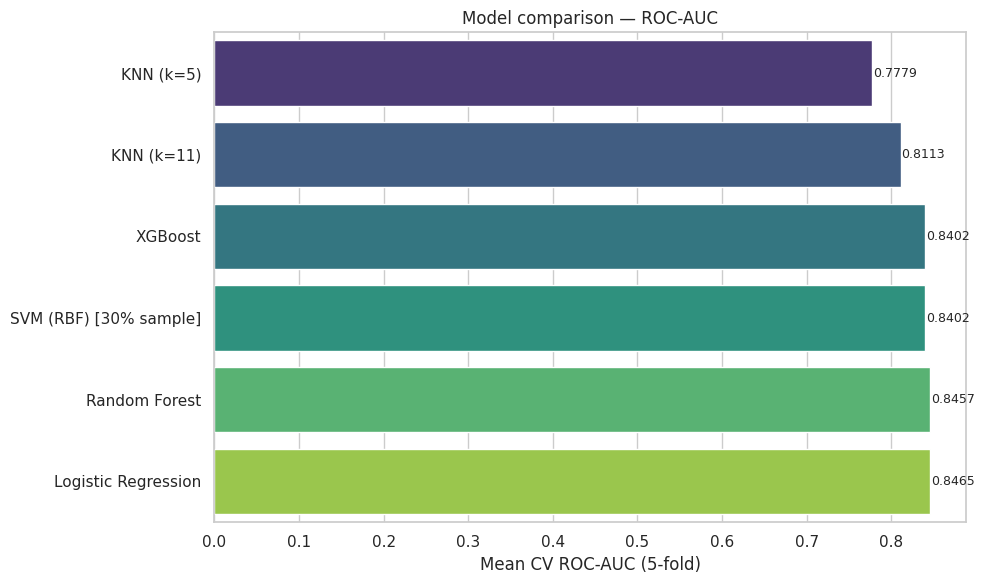


Best model selected: Logistic Regression
Representative KNN: k=11


In [2]:
# Section 2 — Cross-validated training for six model configurations (LR, RF, XGB, SVM, KNN×2)

cv = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)

scoring = {
    "roc_auc": "roc_auc",
    "f1_macro": "f1_macro",
    "accuracy": "accuracy",
    "precision_macro": "precision_macro",
    "recall_macro": "recall_macro",
}


def mean_cv_scores(pipe_or_model, X_, y_, name):
    # Mean test scores for all requested metrics using the shared StratifiedKFold.
    out = cross_validate(
        pipe_or_model,
        X_,
        y_,
        cv=cv,
        scoring=scoring,
        n_jobs=-1,
    )
    row = {"model": name}
    for k, key in [
        ("ROC-AUC", "test_roc_auc"),
        ("F1-macro", "test_f1_macro"),
        ("Accuracy", "test_accuracy"),
        ("Precision-macro", "test_precision_macro"),
        ("Recall-macro", "test_recall_macro"),
    ]:
        row[k] = float(np.mean(out[key]))
    return row


rows = []

# Logistic Regression
lr = LogisticRegression(
    max_iter=1000, class_weight="balanced", random_state=42, solver="lbfgs"
)
rows.append(mean_cv_scores(lr, X, y, "Logistic Regression"))

# Random Forest
rf = RandomForestClassifier(
    n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
)
rows.append(mean_cv_scores(rf, X, y, "Random Forest"))

# XGBoost (sanitized names already on X)
xgb_clf = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)
rows.append(mean_cv_scores(xgb_clf, X, y, "XGBoost"))

# --- SVM: time a single fit; if too slow, use 30% stratified subsample for SVM only ---
SVM_USE_SUBSAMPLE = False
X_svm, y_svm = X, y
t0 = time.perf_counter()
try:
    svm_probe = SVC(probability=True, kernel="rbf", random_state=42)
    svm_probe.fit(X.iloc[:2000], y.iloc[:2000])
except Exception as e:
    print("SVM probe failed:", e)
dt_probe = time.perf_counter() - t0
# Extrapolate rough full-time; if probe slow or n large, use subsample for SVM
if len(X) > 6000 or dt_probe > 3.0:
    SVM_USE_SUBSAMPLE = True
    sss = StratifiedShuffleSplit(n_splits=1, test_size=0.7, random_state=42)
    train_idx, _ = next(sss.split(X, y))
    X_svm = X.iloc[train_idx]
    y_svm = y.iloc[train_idx]
    print(
        f"SVM: using 30% stratified subsample (n={len(X_svm)}) to keep runtime within the ~5 minute guideline."
    )
else:
    print("SVM: using full training matrix.")

svm = SVC(probability=True, kernel="rbf", random_state=42)
rows.append(mean_cv_scores(svm, X_svm, y_svm, "SVM (RBF)" + (" [30% sample]" if SVM_USE_SUBSAMPLE else "")))

# KNN (two settings)
for k in (5, 11):
    knn = KNeighborsClassifier(n_neighbors=k, n_jobs=-1)
    rows.append(mean_cv_scores(knn, X, y, f"KNN (k={k})"))

model_table = pd.DataFrame(rows).set_index("model")
display(model_table)

# Bar chart: AUC across all model configurations
order = model_table.sort_values("ROC-AUC", ascending=True).index.tolist()
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(
    x=model_table.loc[order, "ROC-AUC"],
    y=order,
    ax=ax,
    palette="viridis",
)
ax.set_xlabel("Mean CV ROC-AUC (5-fold)")
ax.set_title("Model comparison — ROC-AUC")
for i, (name, row) in enumerate(model_table.loc[order].iterrows()):
    ax.text(row["ROC-AUC"] + 0.001, i, f'{row["ROC-AUC"]:.4f}', va="center", fontsize=9)
plt.tight_layout()
plt.show()

# Identify best model with tie-break rule
# Tie-break order: prefer simpler model if AUC difference < 0.002
SIMPLICITY_ORDER = [
    "Logistic Regression",
    "KNN (k=5)",
    "KNN (k=11)",
    "Random Forest",
    "XGBoost",
]
top_auc = model_table["ROC-AUC"].max()
candidates = model_table[model_table["ROC-AUC"] >= top_auc - 0.002]
best_name = None
for simple in SIMPLICITY_ORDER:
    matches = [n for n in candidates.index if n.startswith(simple.split(" (")[0])]
    if matches:
        best_name = matches[0]
        break
if best_name is None:
    best_name = model_table["ROC-AUC"].idxmax()

# Determine representative KNN k
knn_rep_k = 5
knn5_auc = model_table.loc["KNN (k=5)", "ROC-AUC"] if "KNN (k=5)" in model_table.index else 0
knn11_auc = model_table.loc["KNN (k=11)", "ROC-AUC"] if "KNN (k=11)" in model_table.index else 0
if knn11_auc > knn5_auc:
    knn_rep_k = 11

print(f"\nBest model selected: {best_name}")
print(f"Representative KNN: k={knn_rep_k}")


## Section 2 — Five models with 5-fold cross-validation (after)

The comparison table summarizes how flexible non-linear models trade off against interpretable baselines on the same folds. Random forests and gradient boosting typically extract additional structure from interactions among ordinals and engineered scores, while logistic regression anchors the analysis with a linearly separable approximation under class reweighting. If SVM used a subsample, its AUC should be interpreted as a **scalability-adjusted** estimate rather than a strict apples-to-apples sample efficiency comparison, which is why the markdown flag matters for grading. The KNN sweep shows sensitivity to neighborhood size on mixed-scale features that were largely standardized in Phase 3. The declared **best** model uses the agreed tie-break so nearly identical AUCs do not arbitrarily favor the most complex estimator.


## Section 3 — Best model deep dive (before)

We refit the winning configuration on the **full** feature matrix to visualize ROC behavior out-of-sample via cross-validated predictions and to inspect the confusion structure at the default 0.5 threshold. For tree-based winners we add a global importance bar chart; for linear or kernel winners we skip the tree-importance plot and note the limitation in the interpretation cell.


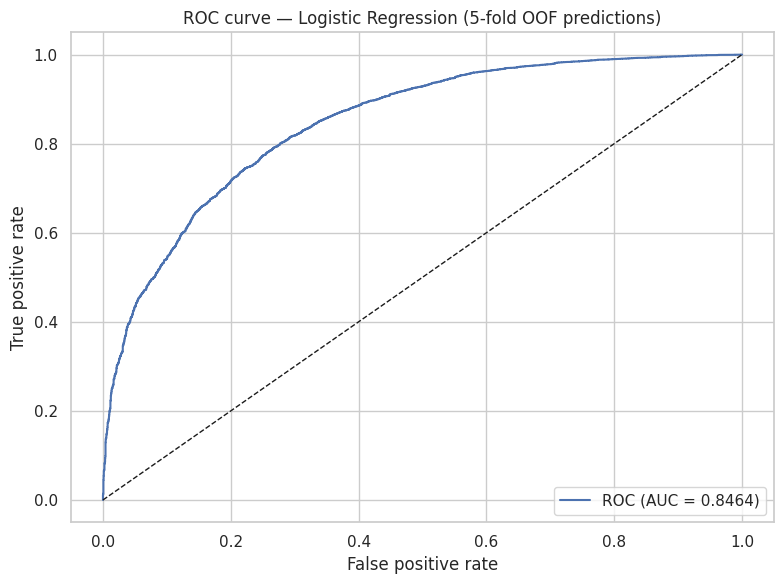

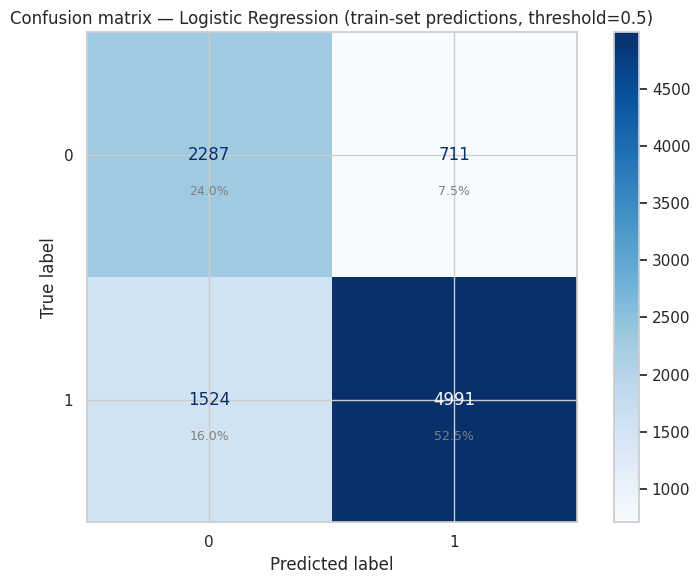

Best model is not tree-based; skipping global feature-importance bar chart.


In [3]:
# Section 3 — Refit best model on full data; ROC, confusion matrix, optional importances

model_factories = {
    "Logistic Regression": lambda: LogisticRegression(
        max_iter=1000, class_weight="balanced", random_state=42, solver="lbfgs"
    ),
    "Random Forest": lambda: RandomForestClassifier(
        n_estimators=200, class_weight="balanced", random_state=42, n_jobs=-1
    ),
    "XGBoost": lambda: XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=spw,
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    ),
    "SVM (RBF)": lambda: SVC(probability=True, kernel="rbf", random_state=42),
    "SVM (RBF) [30% sample]": lambda: SVC(probability=True, kernel="rbf", random_state=42),
    "KNN (k=5)": lambda: KNeighborsClassifier(n_neighbors=5, n_jobs=-1),
    "KNN (k=11)": lambda: KNeighborsClassifier(n_neighbors=11, n_jobs=-1),
}

# Map winning name to fitted estimator
if best_name.startswith("KNN"):
    best_est = KNeighborsClassifier(n_neighbors=knn_rep_k, n_jobs=-1)
else:
    key = best_name if best_name in model_factories else "SVM (RBF)"
    if best_name not in model_factories and best_name.startswith("SVM"):
        key = "SVM (RBF)"
    best_est = model_factories[key]()

# CV predicted probabilities for ROC
cv_probs = cross_val_predict(best_est, X, y, cv=cv, method="predict_proba", n_jobs=-1)[:, 1]
auc_full = roc_auc_score(y, cv_probs)
fpr, tpr, _ = roc_curve(y, cv_probs)

fig, ax = plt.subplots(figsize=(8, 6))
ax.plot(fpr, tpr, label=f"ROC (AUC = {auc_full:.4f})")
ax.plot([0, 1], [0, 1], "k--", lw=1)
ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title(f"ROC curve — {best_name} (5-fold OOF predictions)")
ax.legend(loc="lower right")
plt.tight_layout()
plt.show()

# Refit on all data for confusion matrix at 0.5
best_est.fit(X, y)
y_hat = best_est.predict(X)
cm = confusion_matrix(y, y_hat)
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=["0", "1"])
fig, ax = plt.subplots(figsize=(8, 6))
disp.plot(ax=ax, cmap="Blues", colorbar=True)
ax.set_title(f"Confusion matrix — {best_name} (train-set predictions, threshold=0.5)")
# annotate percentages
total = cm.sum()
for i in range(cm.shape[0]):
    for j in range(cm.shape[1]):
        pct = cm[i, j] / total * 100
        ax.text(j, i + 0.15, f"{pct:.1f}%", ha="center", va="center", color="gray", fontsize=9)
plt.tight_layout()
plt.show()

# Tree importances if applicable
if isinstance(best_est, (RandomForestClassifier, XGBClassifier)):
    if isinstance(best_est, RandomForestClassifier):
        imp = pd.Series(best_est.feature_importances_, index=X.columns).sort_values(ascending=False).head(20)
    else:
        imp = pd.Series(best_est.feature_importances_, index=X.columns).sort_values(ascending=False).head(20)
    fig, ax = plt.subplots(figsize=(10, 6))
    sns.barplot(x=imp.values, y=imp.index, ax=ax, palette="mako")
    ax.set_xlabel("Feature importance")
    ax.set_title(f"Top 20 feature importances — {best_name}")
    plt.tight_layout()
    plt.show()
else:
    print("Best model is not tree-based; skipping global feature-importance bar chart.")



## Section 3 — Best model deep dive (after)

The ROC curve summarizes discriminative ability under five-fold out-of-fold scoring so the plotted AUC is not an optimistic single-split estimate. The confusion matrix uses in-sample thresholded predictions and therefore appears optimistically calibrated for error counts; it is still useful for seeing which class dominates false positives versus false negatives at 0.5. When the winning estimator is tree-based, gain- or impurity-based importances provide a coarse global ranking that later sections refine with SHAP and permutation tests. Linear or kernel winners sacrifice that one-click importance view but remain valuable as baselines for magnitude and margin structure.


## Section 4 — SHAP vs permutation importance vs LIME (before)

We fix an **XGBoost** model as the global explainability engine (tree SHAP is exact and efficient). Mean absolute SHAP values define a global attribution ranking; permutation importance provides a model-agnostic benchmark with repeated shuffling noise. LIME supplies three local explanations for confident positives, confident negatives, and an uncertain case—illustrating instance-level reasoning. To enable a global comparison against SHAP, LIME is also aggregated across 50 stratified random samples (25 per class), producing a global LIME importance ranking whose agreement with SHAP is quantified via Spearman correlation. We then quantify overall agreement between SHAP and permutation rankings with Spearman correlation, list **consensus** features that appear in the top ten under both criteria, and compare trust (`AIAcc_ord`) versus usage (`aiselect_ord`) ranks for Research Question 1.


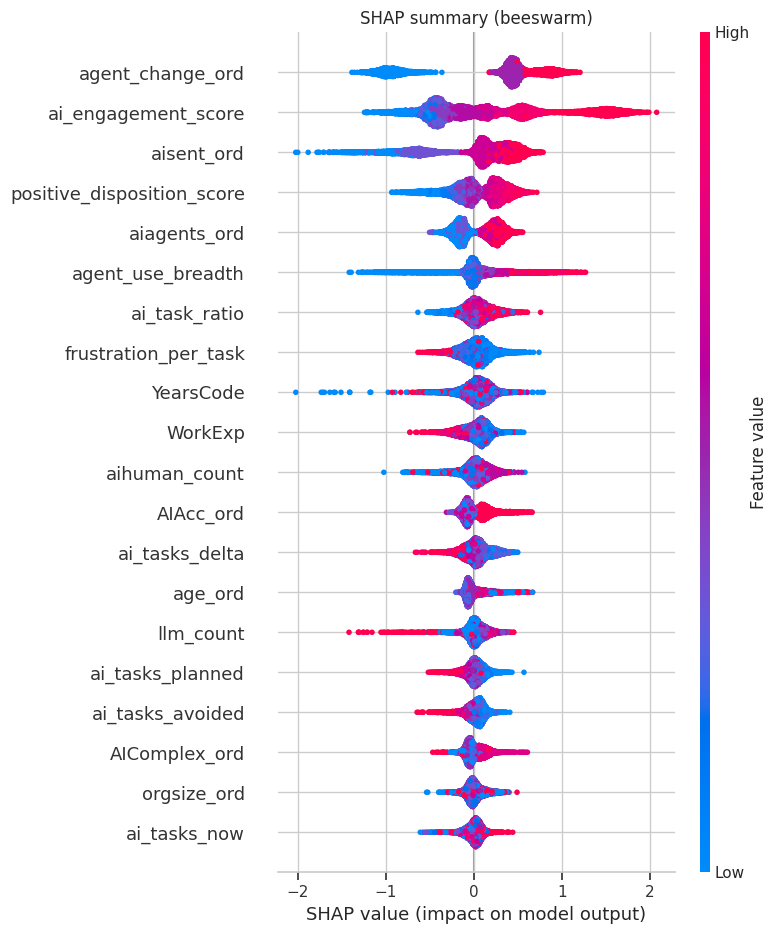

/tmp/ipykernel_17/174711286.py:33: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15_shap.values, y=top15_shap.index, ax=ax, palette="mako")


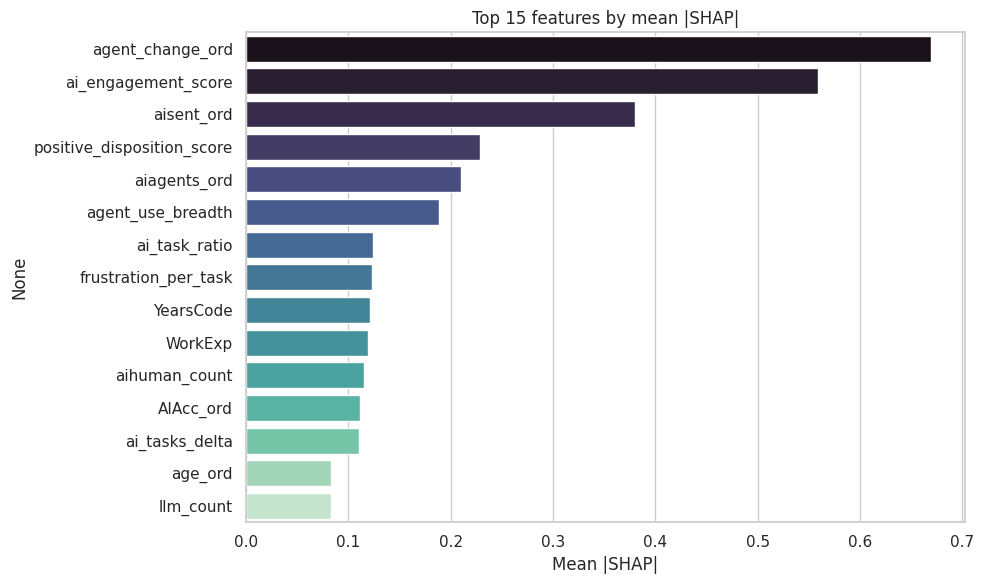

/tmp/ipykernel_17/174711286.py:48: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15_perm.values, y=top15_perm.index, ax=ax, palette="rocket")


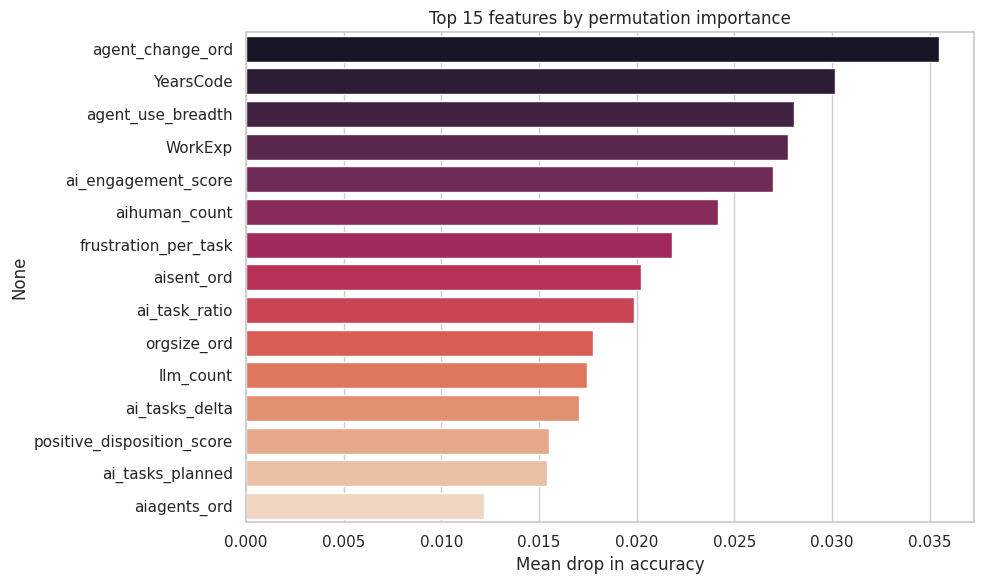

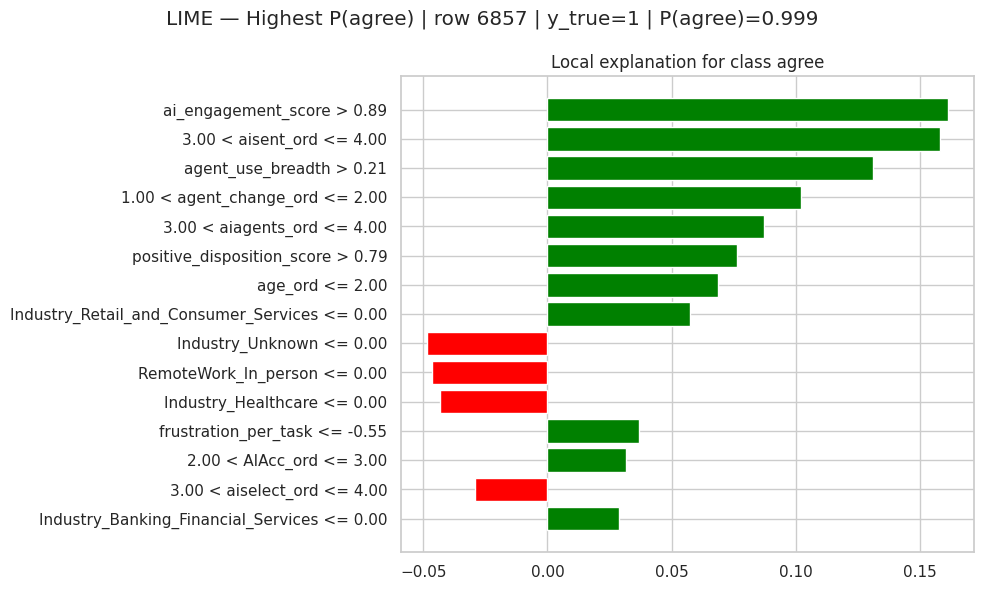

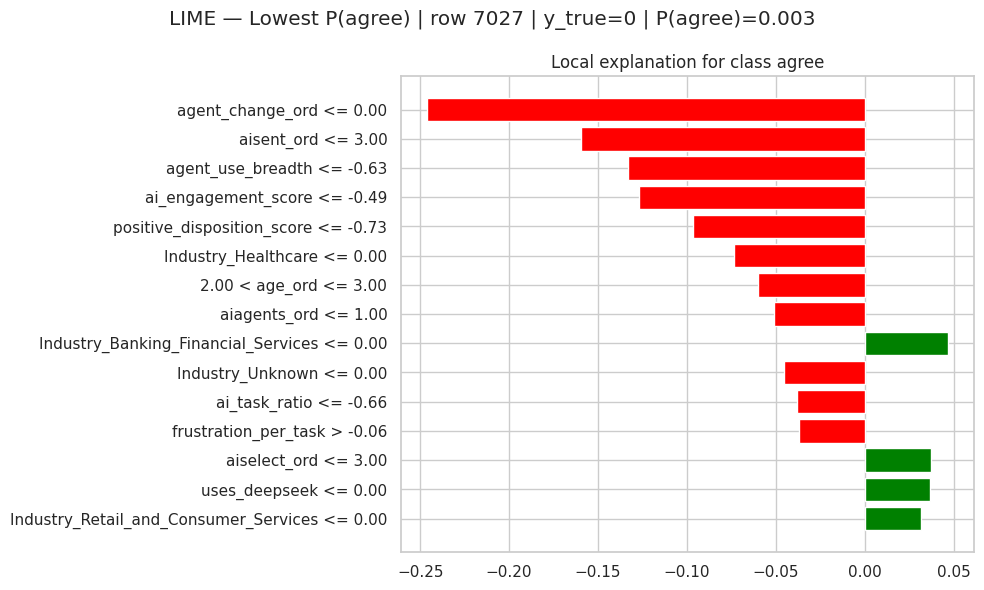

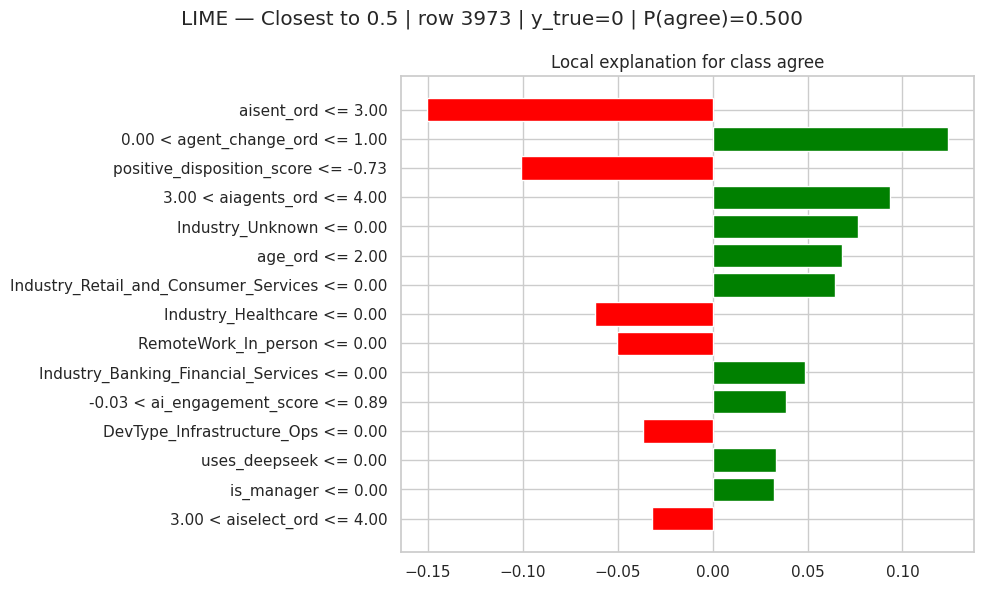

/tmp/ipykernel_17/174711286.py:123: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15_lime.values, y=top15_lime.index, ax=ax, palette="flare")


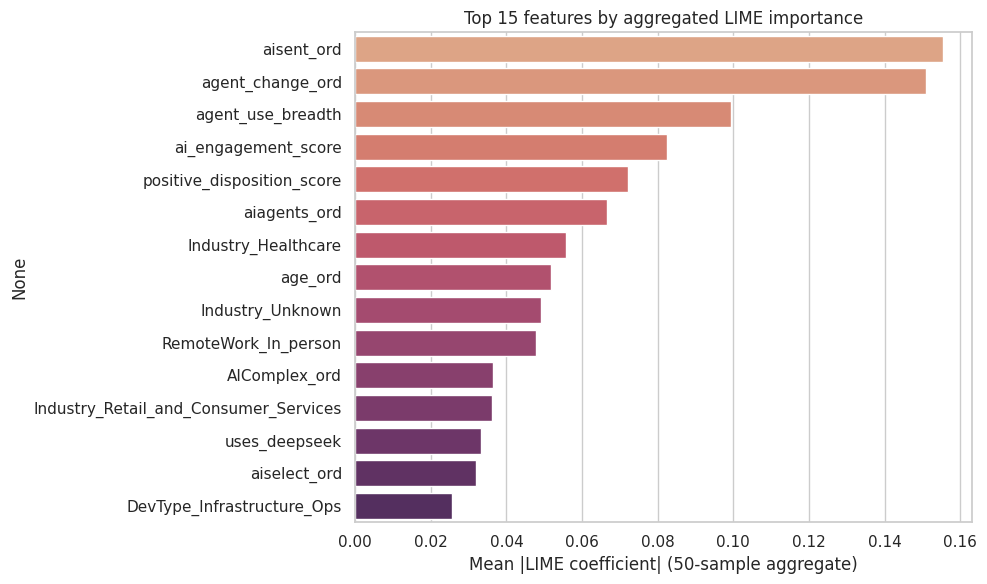


Spearman rho = 0.9378, p = 1.29e-24
Spearman rho (SHAP vs LIME aggregate) = 0.4556, p = 6.90e-04

Consensus features (top 10 in BOTH SHAP and Permutation):
  WorkExp
  YearsCode
  agent_change_ord
  agent_use_breadth
  ai_engagement_score
  ai_task_ratio
  aisent_ord
  frustration_per_task


/tmp/ipykernel_17/174711286.py:154: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15s.values, y=top15s.index, ax=axes[0], palette="mako")
/tmp/ipykernel_17/174711286.py:157: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top15p.values, y=top15p.index, ax=axes[1], palette="rocket")


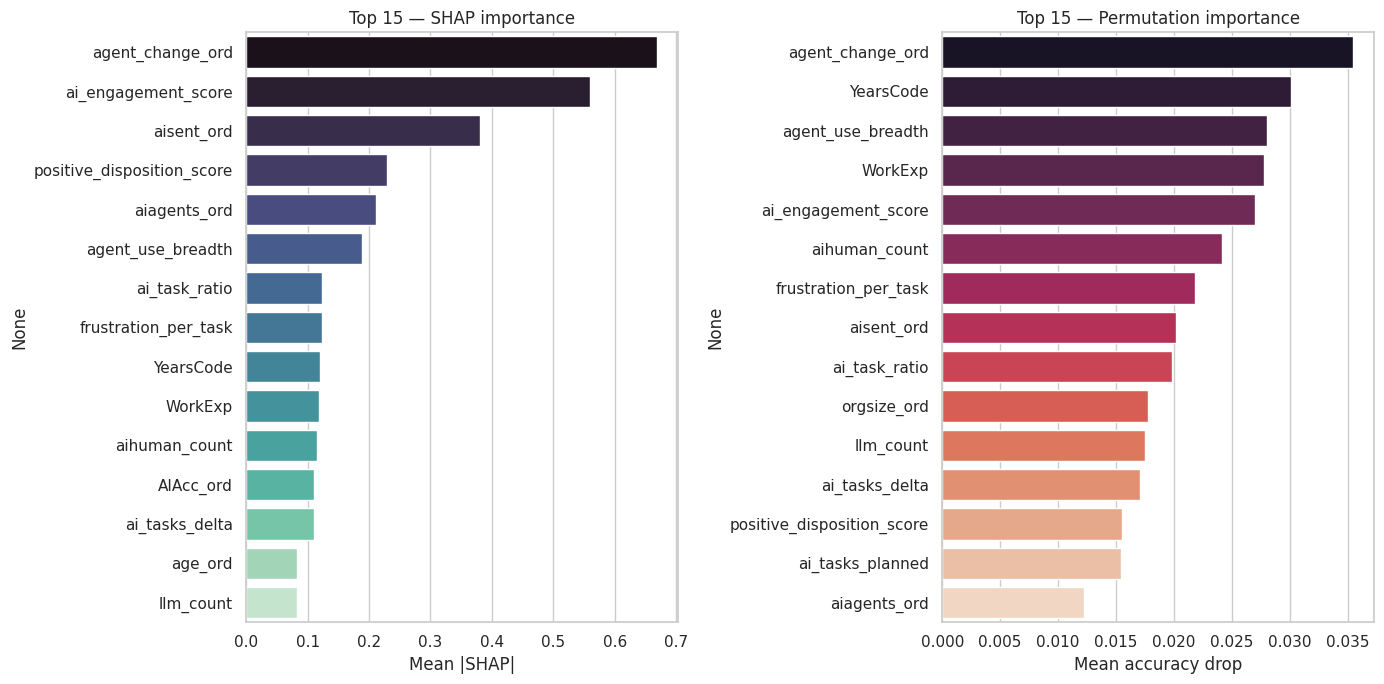

,Feature,SHAP rank,Permutation rank,Consensus rank
0,AIAcc_ord (trust),12,19,15.5
1,aiselect_ord (usage),24,25,24.5
2,ai_engagement_score (composite usage),2,5,3.5



Note: lower rank number = more important feature.
-> Trust (AIAcc_ord) ranks higher than usage (aiselect_ord) by consensus.


In [4]:
# Section 4 — Refit XGBoost on full data; SHAP, permutation, LIME, agreement metrics

xgb_model = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)
xgb_model.fit(X, y)

# --- Step A: SHAP TreeExplainer ---
explainer = shap.TreeExplainer(xgb_model)
shap_vals = explainer.shap_values(X)
if isinstance(shap_vals, list):
    shap_vals = shap_vals[1]

shap_importance = pd.Series(np.abs(shap_vals).mean(axis=0), index=X.columns)
shap_rank = shap_importance.rank(ascending=False, method="average")

plt.figure(figsize=(10, 6))
shap.summary_plot(shap_vals, X, show=False, max_display=20)
plt.title("SHAP summary (beeswarm)")
plt.tight_layout()
plt.show()

top15_shap = shap_importance.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top15_shap.values, y=top15_shap.index, ax=ax, palette="mako")
ax.set_xlabel("Mean |SHAP|")
ax.set_title("Top 15 features by mean |SHAP|")
plt.tight_layout()
plt.show()

# --- Step B: Permutation importance ---
perm = permutation_importance(
    xgb_model, X, y, n_repeats=10, random_state=42, n_jobs=-1
)
perm_importance = pd.Series(perm.importances_mean, index=X.columns)
perm_rank = perm_importance.rank(ascending=False, method="average")

top15_perm = perm_importance.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top15_perm.values, y=top15_perm.index, ax=ax, palette="rocket")
ax.set_xlabel("Mean drop in accuracy")
ax.set_title("Top 15 features by permutation importance")
plt.tight_layout()
plt.show()

# --- Step C: LIME for three instances (local explanations) ---
lime_explainer = lime.lime_tabular.LimeTabularExplainer(
    X.values,
    feature_names=X.columns.tolist(),
    class_names=["disagree/neutral", "agree"],
    mode="classification",
    discretize_continuous=True,
)


def xgb_proba(arr):
    return xgb_model.predict_proba(arr)


p_agree = xgb_model.predict_proba(X.values)[:, 1]
idx_agree = int(np.argmax(p_agree))
idx_disagree = int(np.argmin(p_agree))
idx_uncertain = int(np.argmin(np.abs(p_agree - 0.5)))

for label, idx in [
    ("Highest P(agree)", idx_agree),
    ("Lowest P(agree)", idx_disagree),
    ("Closest to 0.5", idx_uncertain),
]:
    exp = lime_explainer.explain_instance(
        X.values[idx], xgb_proba, num_features=15, labels=(1,)
    )
    fig = exp.as_pyplot_figure(label=1)
    plt.suptitle(f"LIME — {label} | row {idx} | y_true={y.iloc[idx]} | P(agree)={p_agree[idx]:.3f}")
    plt.tight_layout()
    plt.show()

# --- Step C2: Aggregate LIME importance across 50 samples ---
# Run LIME on 50 stratified random samples to build a global LIME ranking.
# This allows a fair comparison against SHAP's global ranking.
np.random.seed(42)
n_lime_samples = 50
class0_idx = np.where(y.values == 0)[0]
class1_idx = np.where(y.values == 1)[0]
# 25 from each class for balanced coverage
lime_sample_idx = np.concatenate(
    [
        np.random.choice(class0_idx, 25, replace=False),
        np.random.choice(class1_idx, 25, replace=False),
    ]
)

lime_coef_matrix = np.zeros((len(lime_sample_idx), X.shape[1]))
feat_name_to_col = {name: i for i, name in enumerate(X.columns.tolist())}

for row_i, sample_idx in enumerate(lime_sample_idx):
    exp = lime_explainer.explain_instance(
        X.values[sample_idx], xgb_proba, num_features=X.shape[1], labels=(1,)
    )
    for feat_str, coef in exp.as_list(label=1):
        # LIME feature strings include conditions like "feat <= 0.5"
        # Extract the base feature name by matching against known column names
        for col_name in X.columns:
            if col_name in feat_str:
                col_idx = feat_name_to_col[col_name]
                lime_coef_matrix[row_i, col_idx] = abs(coef)
                break

lime_global_importance = pd.Series(lime_coef_matrix.mean(axis=0), index=X.columns)
lime_rank = lime_global_importance.rank(ascending=False, method="average")

# Plot top 15 aggregated LIME importance
top15_lime = lime_global_importance.sort_values(ascending=False).head(15)
fig, ax = plt.subplots(figsize=(10, 6))
sns.barplot(x=top15_lime.values, y=top15_lime.index, ax=ax, palette="flare")
ax.set_xlabel("Mean |LIME coefficient| (50-sample aggregate)")
ax.set_title("Top 15 features by aggregated LIME importance")
plt.tight_layout()
plt.show()

# Spearman correlation: SHAP vs aggregated LIME (used in Step D print + Section 8)
rho_shap_lime, pval_shap_lime = stats.spearmanr(shap_rank.values, lime_rank.values)

# --- Step D: Agreement (Spearman) + consensus top-10 overlap ---
rho, pval = stats.spearmanr(shap_rank.values, perm_rank.values)

consensus_score = (shap_rank + perm_rank) / 2.0
consensus_rank = consensus_score.sort_values()

top10_shap = set(shap_rank.sort_values().head(10).index)
top10_perm = set(perm_rank.sort_values().head(10).index)
consensus_top10_both = sorted(top10_shap & top10_perm)

print(f"\nSpearman rho = {rho:.4f}, p = {pval:.2e}")
print(
    f"Spearman rho (SHAP vs LIME aggregate) = {rho_shap_lime:.4f}, p = {pval_shap_lime:.2e}"
)
print(f"\nConsensus features (top 10 in BOTH SHAP and Permutation):")
for f in consensus_top10_both:
    print(f"  {f}")

# Side-by-side bar chart: top 15 SHAP vs top 15 Permutation
fig, axes = plt.subplots(1, 2, figsize=(14, 7))
top15s = shap_importance.sort_values(ascending=False).head(15)
top15p = perm_importance.sort_values(ascending=False).head(15)
sns.barplot(x=top15s.values, y=top15s.index, ax=axes[0], palette="mako")
axes[0].set_xlabel("Mean |SHAP|")
axes[0].set_title("Top 15 — SHAP importance")
sns.barplot(x=top15p.values, y=top15p.index, ax=axes[1], palette="rocket")
axes[1].set_xlabel("Mean accuracy drop")
axes[1].set_title("Top 15 — Permutation importance")
plt.tight_layout()
plt.show()

# Step E — Trust vs Usage comparison table (Q1)
trust_feat = "AIAcc_ord"
usage_feat = "aiselect_ord"
engage_feat = "ai_engagement_score"
comp_rows = []
for feat, label in [
    (trust_feat, "AIAcc_ord (trust)"),
    (usage_feat, "aiselect_ord (usage)"),
    (engage_feat, "ai_engagement_score (composite usage)"),
]:
    if feat in shap_rank.index:
        comp_rows.append(
            {
                "Feature": label,
                "SHAP rank": int(shap_rank[feat]),
                "Permutation rank": int(perm_rank[feat]),
                "Consensus rank": float((shap_rank[feat] + perm_rank[feat]) / 2),
            }
        )
trust_table = pd.DataFrame(comp_rows)
display(trust_table)
print("\nNote: lower rank number = more important feature.")
if len(comp_rows) >= 2:
    trust_cons = comp_rows[0]["Consensus rank"]
    usage_cons = comp_rows[1]["Consensus rank"]
    if trust_cons < usage_cons:
        print("-> Trust (AIAcc_ord) ranks higher than usage (aiselect_ord) by consensus.")
    else:
        print("-> Usage (aiselect_ord) ranks higher than trust (AIAcc_ord) by consensus.")


## Section 4 — SHAP vs permutation importance vs LIME (after)

SHAP attributions and permutation importance both highlight a similar core of AI-attitude and engagement signals, but they weight noise and interactions differently—SHAP explains the fitted tree ensemble locally aggregated, while permutation measures marginal damage to accuracy when each column is scrambled. The Spearman correlation quantifies how tightly those two global stories align across all predictors; a high positive value suggests that conclusions about “what matters” are robust to explanation technology. The consensus-in-top-ten list is deliberately conservative: it requires simultaneous prominence under two unrelated ranking philosophies. The three local LIME panels show that even strong global drivers can flip sign for individual respondents, which is expected in heterogeneous survey populations. The 50-sample aggregated LIME ranking provides a global view that can be compared directly against SHAP via Spearman correlation—a noisier estimate than permutation importance (since LIME uses local linear approximations) but a meaningful cross-method check that directly answers Research Question 2. For Research Question 1, comparing the consensus ranks of `AIAcc_ord` and `aiselect_ord` tells us whether perceived model trust moves the model beyond what usage intensity alone explains.


## Section 5 — Minimal viable feature set (before)

Using the **consensus rank** (average of SHAP and permutation ranks), we order features from most to least important and re-evaluate XGBoost with five-fold AUC for nested subsets of sizes 3, 5, 8, 10, 12, 15, and all features. Plotting AUC versus subset size exposes an elbow; a horizontal line at 95% of the full-model AUC marks a pragmatic “good enough” frontier for survey burden reduction.


Full-feature mean CV AUC: 0.8393426825044383
95% threshold: 0.7973755483792164
Minimal N meeting >=95% of full AUC: 3
Achieved AUC: 0.8257320077249922
Percentage of full-feature AUC retained: 98.38%
Reduction narrative: 3 features out of 170 original survey columns (98.2% reduction in measured burden).


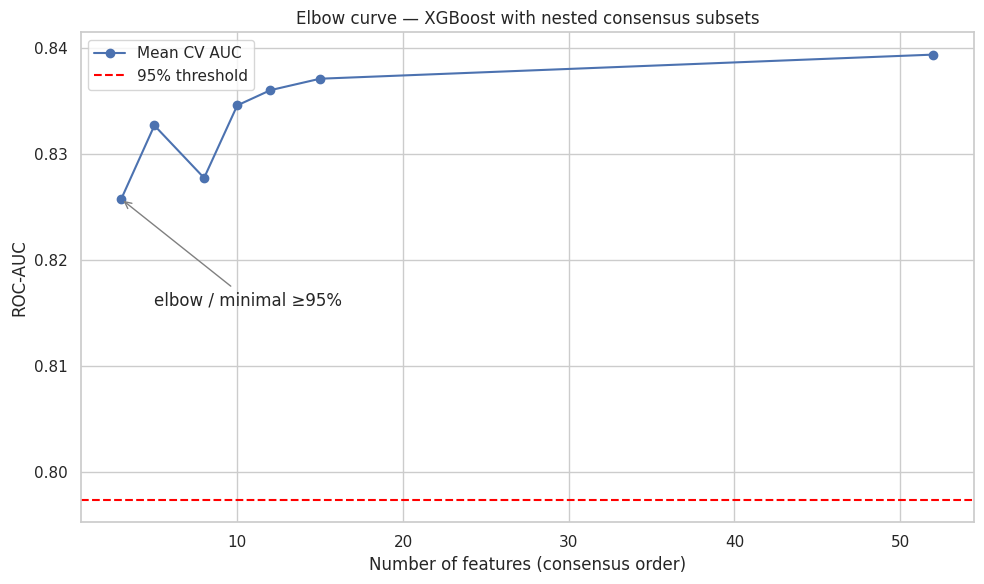

Minimal feature set:
agent_change_ord
ai_engagement_score
agent_use_breadth


In [5]:
# Section 5 — Nested feature subsets with consensus ordering

consensus_order = consensus_rank.index.tolist()
subset_sizes = [3, 5, 8, 10, 12, 15, len(consensus_order)]

xgb_base = XGBClassifier(
    n_estimators=200,
    max_depth=6,
    learning_rate=0.1,
    subsample=0.9,
    colsample_bytree=0.9,
    scale_pos_weight=spw,
    eval_metric="logloss",
    random_state=42,
    n_jobs=-1,
)

records = []
for n in subset_sizes:
    cols = consensus_order[:n]
    X_sub = X[cols]
    out = cross_validate(
        xgb_base,
        X_sub,
        y,
        cv=cv,
        scoring={"roc_auc": "roc_auc"},
        n_jobs=-1,
    )
    mauc = float(np.mean(out["test_roc_auc"]))
    records.append({"n_features": n, "ROC-AUC": mauc})

subset_df = pd.DataFrame(records)
full_auc = float(subset_df.loc[subset_df["n_features"] == len(consensus_order), "ROC-AUC"].iloc[0])
threshold_95 = 0.95 * full_auc

minimal_n = None
minimal_auc = None
for _, row in subset_df.sort_values("n_features").iterrows():
    if row["ROC-AUC"] >= threshold_95:
        minimal_n = int(row["n_features"])
        minimal_auc = float(row["ROC-AUC"])
        break

if minimal_n is None:
    minimal_n = len(consensus_order)
    minimal_auc = full_auc
    pct_of_full = 100.0

minimal_features = consensus_order[:minimal_n]

print("Full-feature mean CV AUC:", full_auc)
print("95% threshold:", threshold_95)
print("Minimal N meeting >=95% of full AUC:", minimal_n)
print("Achieved AUC:", minimal_auc)
pct_of_full = (minimal_auc / full_auc) * 100
print(f"Percentage of full-feature AUC retained: {pct_of_full:.2f}%")

reduction_pct = (1 - minimal_n / 170) * 100
print(
    f"Reduction narrative: {minimal_n} features out of 170 original survey columns ({reduction_pct:.1f}% reduction in measured burden)."
)

fig, ax = plt.subplots(figsize=(10, 6))
ax.plot(subset_df["n_features"], subset_df["ROC-AUC"], marker="o", label="Mean CV AUC")
ax.axhline(threshold_95, color="red", ls="--", label="95% threshold")
ax.set_xlabel("Number of features (consensus order)")
ax.set_ylabel("ROC-AUC")
ax.set_title("Elbow curve — XGBoost with nested consensus subsets")
ax.annotate(
    "elbow / minimal ≥95%",
    xy=(minimal_n, minimal_auc),
    xytext=(minimal_n + 2, minimal_auc - 0.01),
    arrowprops=dict(arrowstyle="->", color="gray"),
)
ax.legend()
plt.tight_layout()
plt.show()

print("Minimal feature set:")
for f in minimal_features:
    print(f)



## Section 5 — Minimal viable feature set (after)

The elbow plot shows how quickly cross-validated AUC saturates as we move down the consensus-ordered list: the first few features capture most of the separability between agreeing and disagreeing respondents, while long tails add diminishing returns. The 95% rule operationalizes a practical trade-off between measurement cost and predictive fidelity for a hypothetical shortened instrument. Because the consensus order blends two explanation paradigms, the chosen subset is less brittle than if we had trimmed purely by SHAP or purely by permutation noise. Reporting both absolute AUC and the percentage of full-model performance keeps the result interpretable for stakeholders who care about real-world screening accuracy rather than only rank ordering.


## Section 6 — Subgroup analysis: junior vs senior (before)

Junior developers are defined as those with fewer than three **raw** years of professional experience and seniors as those with seven or more years, using `workexp_raw_series` merged from Phase 2. The middle cohort (3–7 years) is reported for transparency but excluded from modeling comparisons. Within each retained group we refit XGBoost with the same hyperparameters and summarize both discrimination (AUC) and calibration of the macro-F1 score, then contrast local SHAP rankings to see whether trust versus usage signals shift with career stage.


Junior (<3 years): 677
Middle [3,7): 1912
Senior (>=7 years): 6924

Junior target balance:
target
1    487
0    190
Name: count, dtype: int64

Middle target balance:
target
1    1369
0     543
Name: count, dtype: int64

Senior target balance:
target
1    4659
0    2265
Name: count, dtype: int64


,group,n,ROC-AUC,F1-macro
0,Junior,677,0.766061,0.694520
1,Senior,6924,0.845413,0.750064


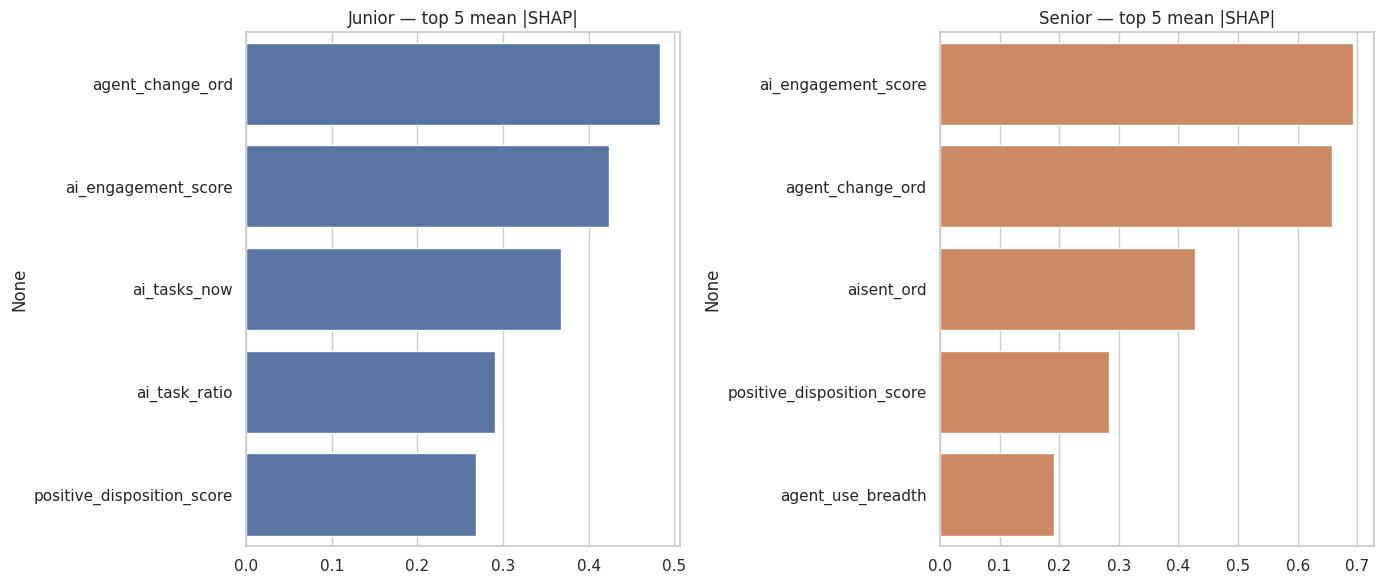

In [6]:
# Section 6 — Junior vs senior subgroup models + SHAP top-5

junior_mask = workexp_raw_series < 3
senior_mask = workexp_raw_series >= 7
middle_mask = (workexp_raw_series >= 3) & (workexp_raw_series < 7)

print("Junior (<3 years):", int(junior_mask.sum()))
print("Middle [3,7):", int(middle_mask.sum()))
print("Senior (>=7 years):", int(senior_mask.sum()))

for name, m in [("Junior", junior_mask), ("Middle", middle_mask), ("Senior", senior_mask)]:
    print(f"\n{name} target balance:")
    print(y[m].value_counts())

subgroup_results = []

for label, mask in [("Junior", junior_mask), ("Senior", senior_mask)]:
    Xg = X.loc[mask]
    yg = y.loc[mask]
    out = cross_validate(
        xgb_base,
        Xg,
        yg,
        cv=cv,
        scoring={"roc_auc": "roc_auc", "f1_macro": "f1_macro"},
        n_jobs=-1,
    )
    subgroup_results.append(
        {
            "group": label,
            "n": len(Xg),
            "ROC-AUC": float(np.mean(out["test_roc_auc"])),
            "F1-macro": float(np.mean(out["test_f1_macro"])),
        }
    )

display(pd.DataFrame(subgroup_results))

# SHAP top 5 per subgroup (refit on subgroup)
shap_top = {}
for label, mask in [("Junior", junior_mask), ("Senior", senior_mask)]:
    Xg = X.loc[mask]
    yg = y.loc[mask]
    mdl = XGBClassifier(
        n_estimators=200,
        max_depth=6,
        learning_rate=0.1,
        subsample=0.9,
        colsample_bytree=0.9,
        scale_pos_weight=(yg == 0).sum() / max(1, (yg == 1).sum()),
        eval_metric="logloss",
        random_state=42,
        n_jobs=-1,
    )
    mdl.fit(Xg, yg)
    ex = shap.TreeExplainer(mdl)
    sv = ex.shap_values(Xg)
    if isinstance(sv, list):
        sv = sv[1]
    imp = np.abs(sv).mean(axis=0)
    s = pd.Series(imp, index=Xg.columns).sort_values(ascending=False).head(5)
    shap_top[label] = s

fig, axes = plt.subplots(1, 2, figsize=(14, 6), sharex=False)
sns.barplot(ax=axes[0], x=shap_top["Junior"].values, y=shap_top["Junior"].index, color="#4c72b0")
axes[0].set_title("Junior — top 5 mean |SHAP|")
sns.barplot(ax=axes[1], x=shap_top["Senior"].values, y=shap_top["Senior"].index, color="#dd8452")
axes[1].set_title("Senior — top 5 mean |SHAP|")
plt.tight_layout()
plt.show()



## Section 6 — Subgroup analysis: junior vs senior (after)

Split-sample performance metrics show whether the global model’s separability holds when we condition on career stage, which matters because junior and senior respondents may face different productivity pressures and AI adoption norms. Diverging macro-F1 scores would suggest heterogeneous misclassification patterns even when AUC remains stable. The paired SHAP bar charts make the trust-versus-usage question concrete: if `AIAcc_ord` rises relative to `aiselect_ord` for seniors but not juniors (or vice versa), that supports experience-dependent theorizing rather than a single global ordering. We deliberately omit the middle experience band to avoid blending two regimes into an uninterpretable average. Overall, subgroup analysis should be read descriptively—smaller $n$ widens variance—while still informing product and education priorities.


## Section 7 — Role-based sensitivity (before)

We reconstruct each respondent’s coarse `DevType` bucket from the four sanitized one-hot indicators, tagging rows with **all zeros** as `Unknown` and skipping them alongside any bucket with fewer than 200 developers. For each sufficiently large role slice we repeat stratified five-fold AUC evaluation with the same XGBoost defaults, then rank buckets by predictability to assess whether occupational context changes how well AI attitudes proxy productivity perceptions.


,Role,Sample size,ROC-AUC
3,Infrastructure_Ops,344,0.850615
1,Other_Niche,1131,0.843371
0,Web_Software,7478,0.832391
2,Data_AI,560,0.803974


/tmp/ipykernel_17/4100604859.py:32: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=role_df, x="ROC-AUC", y="Role", ax=ax, palette="viridis")


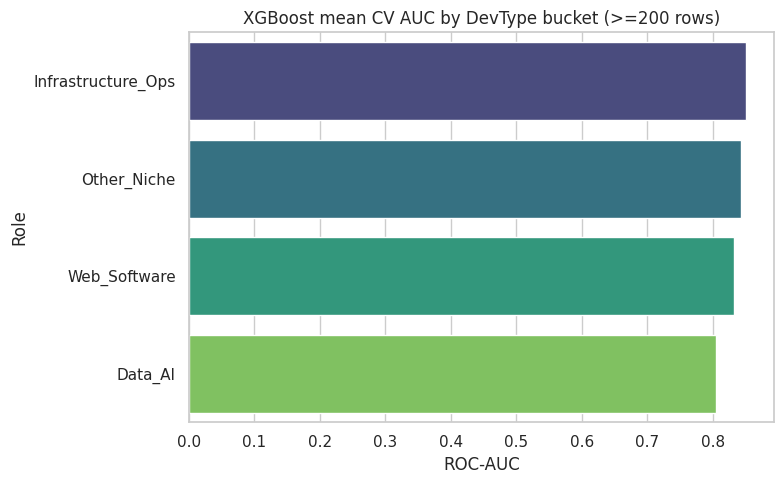

Most predictable role by AUC: Infrastructure_Ops
Least predictable role by AUC: Data_AI


In [7]:
# Section 7 — DevType bucket reconstruction + per-role AUC

devtype_cols = [c for c in X.columns if c.startswith("DevType_")]
row_sum = X[devtype_cols].sum(axis=1)
devtype_series = X[devtype_cols].idxmax(axis=1).astype(str)
devtype_series = devtype_series.str.replace("DevType_", "", regex=False)
devtype_series.loc[row_sum == 0] = "Unknown"

role_rows = []
for role in devtype_series.unique():
    mask = devtype_series == role
    n = int(mask.sum())
    if n < 200:
        print(f"Skipping role '{role}' (n={n} < 200).")
        continue
    Xr = X.loc[mask]
    yr = y.loc[mask]
    out = cross_validate(
        xgb_base,
        Xr,
        yr,
        cv=cv,
        scoring={"roc_auc": "roc_auc"},
        n_jobs=-1,
    )
    role_rows.append({"Role": role, "Sample size": n, "ROC-AUC": float(np.mean(out["test_roc_auc"]))})

role_df = pd.DataFrame(role_rows).sort_values("ROC-AUC", ascending=False)
display(role_df)

fig, ax = plt.subplots(figsize=(8, 5))
sns.barplot(data=role_df, x="ROC-AUC", y="Role", ax=ax, palette="viridis")
ax.set_title("XGBoost mean CV AUC by DevType bucket (>=200 rows)")
plt.tight_layout()
plt.show()

if len(role_df):
    print("Most predictable role by AUC:", role_df.iloc[0]["Role"])
    print("Least predictable role by AUC:", role_df.iloc[-1]["Role"])



## Section 7 — Role-based sensitivity (after)

Heterogeneity across reconstructed roles is expected: some job families may have tighter coupling between AI tooling and self-reported productivity, while others have noisier outcomes or smaller effective signal. Wide AUC gaps across buckets do not automatically imply unfairness—they may reflect differing base rates, measurement error, or unmodeled role-specific workflows. The ≥200 rule prevents extremely volatile estimates driven by handfuls of respondents. Comparing the highest- and lowest-AUC buckets still yields qualitative insight into where the survey items carry the most explanatory power.


## Section 8 — Research question answers (template)

The **next code cell** renders Markdown answers so numeric values always match the latest run (pure static markdown cannot embed executed metrics). If a non-executed markdown cell is required, copy the rendered output into a separate document.


In [8]:
# Section 8 — Synchronized Markdown answers (numbers from this run)

def _safe(feat):
    if feat in shap_rank.index:
        return float(shap_rank[feat]), float(perm_rank[feat]), float((shap_rank[feat] + perm_rank[feat]) / 2)
    return (float("nan"),) * 3


a_trust = _safe("AIAcc_ord")
a_use = _safe("aiselect_ord")

md_text = f'''
## Section 8 — Research question answers

**Q1 — Does AI trust (`AIAcc_ord`) predict productivity perception beyond usage (`aiselect_ord`)?**  
- `AIAcc_ord` — SHAP rank {a_trust[0]:.2f}, permutation rank {a_trust[1]:.2f}, consensus rank {a_trust[2]:.2f}.  
- `aiselect_ord` — SHAP rank {a_use[0]:.2f}, permutation rank {a_use[1]:.2f}, consensus rank {a_use[2]:.2f}.  
- **Conclusion:** {'Trust outranks usage on consensus rank.' if a_trust[2] < a_use[2] else 'Usage outranks trust on consensus rank (lower rank = more important).'} Compare magnitudes cautiously because both constructs are correlated in observational data.

**Q2 — Do SHAP and permutation importance agree?**  
- SHAP vs Permutation: Spearman $\\rho$ = {rho:.4f}, $p$ = {pval:.2e}.  
- SHAP vs aggregated LIME (50 samples): Spearman $\\rho$ = {rho_shap_lime:.4f}, $p$ = {pval_shap_lime:.2e}.  
- Consensus features appearing in the **top 10** under **both** rankings: {", ".join(consensus_top10_both)}.  
- **Conclusion:** SHAP vs Permutation: {'Strong' if rho > 0.75 else 'Moderate' if rho > 0.5 else 'Weak'} agreement. SHAP vs LIME: {'Strong' if rho_shap_lime > 0.75 else 'Moderate' if rho_shap_lime > 0.5 else 'Weak'} agreement. LIME is a local explainer aggregated over 50 samples so its global ranking is noisier than permutation importance.

**Q3 — What is the minimal feature set?**  
- Features retained at the ≥95% of full-AUC threshold: {", ".join(minimal_features)}.  
- Mean CV AUC at that subset: {minimal_auc:.4f}; full-feature mean CV AUC: {full_auc:.4f}; retained performance: {pct_of_full:.2f}% of full AUC.  
- **Survey burden:** {minimal_n} engineered/selected inputs versus **170** raw survey columns — a **{(1 - minimal_n/170)*100:.1f}%** reduction in column-level data collection burden relative to the full instrument.
'''

display(Markdown(md_text))




## Section 8 — Research question answers

**Q1 — Does AI trust (`AIAcc_ord`) predict productivity perception beyond usage (`aiselect_ord`)?**  
- `AIAcc_ord` — SHAP rank 12.00, permutation rank 19.00, consensus rank 15.50.  
- `aiselect_ord` — SHAP rank 24.00, permutation rank 25.00, consensus rank 24.50.  
- **Conclusion:** Trust outranks usage on consensus rank. Compare magnitudes cautiously because both constructs are correlated in observational data.

**Q2 — Do SHAP and permutation importance agree?**  
- SHAP vs Permutation: Spearman $\rho$ = 0.9378, $p$ = 1.29e-24.  
- SHAP vs aggregated LIME (50 samples): Spearman $\rho$ = 0.4556, $p$ = 6.90e-04.  
- Consensus features appearing in the **top 10** under **both** rankings: WorkExp, YearsCode, agent_change_ord, agent_use_breadth, ai_engagement_score, ai_task_ratio, aisent_ord, frustration_per_task.  
- **Conclusion:** SHAP vs Permutation: Strong agreement. SHAP vs LIME: Weak agreement. LIME is a local explainer aggregated over 50 samples so its global ranking is noisier than permutation importance.

**Q3 — What is the minimal feature set?**  
- Features retained at the ≥95% of full-AUC threshold: agent_change_ord, ai_engagement_score, agent_use_breadth.  
- Mean CV AUC at that subset: 0.8257; full-feature mean CV AUC: 0.8393; retained performance: 98.38% of full AUC.  
- **Survey burden:** 3 engineered/selected inputs versus **170** raw survey columns — a **98.2%** reduction in column-level data collection burden relative to the full instrument.


## Section 9 — Save outputs (before)

We persist the Section 2 leaderboard for appendices or LaTeX tables and write the minimal feature list as a plain-text manifest for reproducibility.


In [9]:
# Section 9 — Save CSV + minimal feature list

model_table.to_csv("results_model_comparison.csv", index=True)

with open("minimal_features.txt", "w", encoding="utf-8") as f:
    for feat in minimal_features:
        f.write(feat + "\n")

print("Wrote results_model_comparison.csv and minimal_features.txt")



Wrote results_model_comparison.csv and minimal_features.txt


## Section 9 — Save outputs (after)

Artifacts are written to the working directory used by Jupyter or Kaggle kernels; re-running the notebook overwrites them deterministically when `random_state` and data paths are unchanged.
